In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.model_selection import cross_validate

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    make_scorer
)

import warnings
warnings.filterwarnings("ignore")

print("Semua library berhasil diimpor")

Semua library berhasil diimpor


In [2]:
df = pd.read_csv("original.csv")

# Membersihkan karakter BOM pada nama kolom
df.columns = df.columns.str.replace("ï»¿", "", regex=False)

print("Dataset berhasil dimuat")

Dataset berhasil dimuat


In [3]:
print("Jumlah Baris dan Kolom:")
print(df.shape)

print("\nJumlah Baris:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

Jumlah Baris dan Kolom:
(80, 20)

Jumlah Baris: 80
Jumlah Kolom: 20


In [4]:
print("Tipe Data Setiap Kolom:")
display(df.dtypes.to_frame(name="Tipe Data"))

Tipe Data Setiap Kolom:


,Tipe Data
Gender,int64
Age,int64
POLAR4 Quintile,int64
POLAR3 Quintile,int64
Adult HE 2001 Quintile,int64
Adult HE 2011 Quintile,int64
TUNDRA MSOA Quintile,int64
TUNDRA LSOA Quintile,int64
Gaps GCSE Quintile,int64
Gaps GCSE Ethnicity Quintile,int64


In [5]:
print("Lima Baris Pertama Dataset:")
display(df.head())

Lima Baris Pertama Dataset:


,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)"
0,0,38,5,5,4,5,4,4,5,5,0,1,13.333806,19,7.41,0.620767,3,9.0,25.000000,1
1,0,22,4,2,1,3,4,4,4,5,0,1,15.844126,1,0.03,0.002513,0,12.0,0.000000,1
2,0,21,4,5,4,5,4,4,5,5,0,1,17.706573,25,6.14,0.514374,5,7.0,41.666667,1
3,0,25,5,4,3,4,3,3,5,5,0,0,17.327498,3,0.16,0.013404,0,12.0,0.000000,1
4,0,20,5,4,3,4,3,3,4,4,0,1,0.000000,25,4.03,0.337610,11,1.0,91.666667,1


In [6]:
print("Daftar Nama Kolom:")

for kolom in df.columns:
    print(kolom)

Daftar Nama Kolom:
Gender
Age
POLAR4 Quintile
POLAR3 Quintile
Adult HE 2001 Quintile
Adult HE 2011 Quintile
TUNDRA MSOA Quintile
TUNDRA LSOA Quintile
Gaps GCSE Quintile
Gaps GCSE Ethnicity Quintile
Uni Connect target ward
attending from home?
distance to university (km)
Count of Module Area Logins
Total Hours in Module Area
% of Average Hours in Module Area
# of presence
# of Absence
Percent Attended
label (fail=1, pass=0)


In [7]:
target = "label (fail=1, pass=0)"

print("Distribusi Label:")
display(df[target].value_counts())

print("\nPersentase Label:")
display(df[target].value_counts(normalize=True) * 100)

Distribusi Label:


label (fail=1, pass=0)
0    68
1    12
Name: count, dtype: int64


Persentase Label:


label (fail=1, pass=0)
0    85.0
1    15.0
Name: proportion, dtype: float64

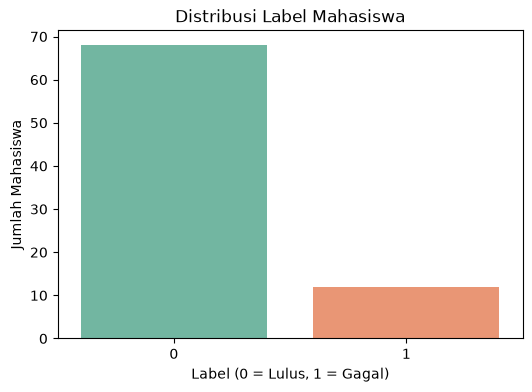

In [8]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x=target,
    hue=target,
    palette="Set2",
    legend=False
)

plt.title("Distribusi Label Mahasiswa")
plt.xlabel("Label (0 = Lulus, 1 = Gagal)")
plt.ylabel("Jumlah Mahasiswa")

plt.show()

#EDA dan Pemrosesan Data

In [11]:
print("Jumlah Baris Kosong:")
print(df.isna().all(axis=1).sum())

print("\nJumlah Kolom Kosong:")
print(df.isna().all(axis=0).sum())

print("\nJumlah Missing Value Setiap Kolom:")
display(df.isnull().sum())

Jumlah Baris Kosong:
0

Jumlah Kolom Kosong:
0

Jumlah Missing Value Setiap Kolom:


Gender                               0
Age                                  0
POLAR4 Quintile                      0
POLAR3 Quintile                      0
Adult HE 2001 Quintile               0
Adult HE 2011 Quintile               0
TUNDRA MSOA Quintile                 0
TUNDRA LSOA Quintile                 0
Gaps GCSE Quintile                   0
Gaps GCSE Ethnicity Quintile         0
Uni Connect target ward              0
attending from home?                 0
distance to university (km)          0
Count of Module Area Logins          0
Total Hours in Module Area           0
% of Average Hours in Module Area    0
# of presence                        0
# of Absence                         2
Percent Attended                     0
label (fail=1, pass=0)               0
dtype: int64

In [12]:
df = df.dropna(how="all")

df = df.dropna(axis=1, how="all")

print("Dimensi Setelah Menghapus Data Kosong:")
print(df.shape)

Dimensi Setelah Menghapus Data Kosong:
(80, 20)


In [13]:
print("Jumlah Data Duplikat:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDimensi Setelah Menghapus Duplikat:")
print(df.shape)

Jumlah Data Duplikat:
0

Dimensi Setelah Menghapus Duplikat:
(80, 20)


In [14]:
quintile_cols = [
    col for col in df.columns
    if "Quintile" in col
]

for col in quintile_cols:
    print("\nKolom:", col)
    print(df[col].value_counts(dropna=False).sort_index())


Kolom: POLAR4 Quintile
POLAR4 Quintile
1    11
2    10
3    10
4    20
5    29
Name: count, dtype: int64

Kolom: POLAR3 Quintile
POLAR3 Quintile
1    14
2    11
3    13
4    22
5    20
Name: count, dtype: int64

Kolom: Adult HE 2001 Quintile
Adult HE 2001 Quintile
1    19
2    12
3    25
4    21
5     3
Name: count, dtype: int64

Kolom: Adult HE 2011 Quintile
Adult HE 2011 Quintile
0     2
1    11
2    11
3     8
4    35
5    13
Name: count, dtype: int64

Kolom: TUNDRA MSOA Quintile
TUNDRA MSOA Quintile
0     2
1    17
2     5
3    28
4    23
5     5
Name: count, dtype: int64

Kolom: TUNDRA LSOA Quintile
TUNDRA LSOA Quintile
0     2
1    17
2     5
3    28
4    23
5     5
Name: count, dtype: int64

Kolom: Gaps GCSE Quintile
Gaps GCSE Quintile
0     4
1     7
2     6
3    13
4    16
5    34
Name: count, dtype: int64

Kolom: Gaps GCSE Ethnicity Quintile
Gaps GCSE Ethnicity Quintile
0     4
1     3
2     5
3     6
4    12
5    50
Name: count, dtype: int64


In [15]:
for col in quintile_cols:
    df.loc[df[col] == 0, col] = np.nan

print("Nilai 0 pada kolom kuintil telah diubah menjadi NaN")

display(df[quintile_cols].isnull().sum())

Nilai 0 pada kolom kuintil telah diubah menjadi NaN


POLAR4 Quintile                 0
POLAR3 Quintile                 0
Adult HE 2001 Quintile          0
Adult HE 2011 Quintile          2
TUNDRA MSOA Quintile            2
TUNDRA LSOA Quintile            2
Gaps GCSE Quintile              4
Gaps GCSE Ethnicity Quintile    4
dtype: int64

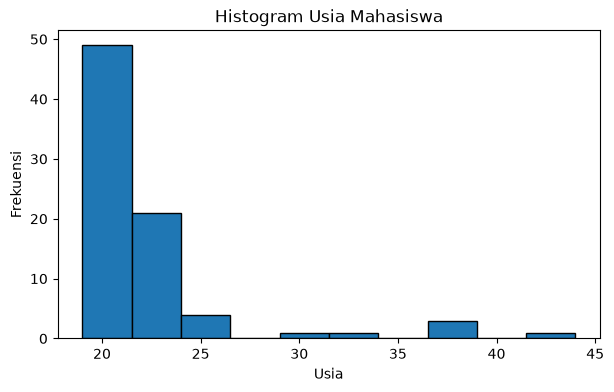

In [16]:
plt.figure(figsize=(7,4))

plt.hist(
    df["Age"],
    bins=10,
    edgecolor="black"
)

plt.title("Histogram Usia Mahasiswa")
plt.xlabel("Usia")
plt.ylabel("Frekuensi")

plt.show()

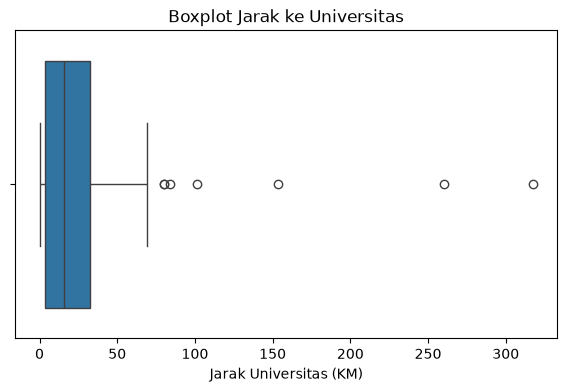

In [17]:
plt.figure(figsize=(7,4))

sns.boxplot(
    x=df["distance to university (km)"]
)

plt.title("Boxplot Jarak ke Universitas")
plt.xlabel("Jarak Universitas (KM)")

plt.show()

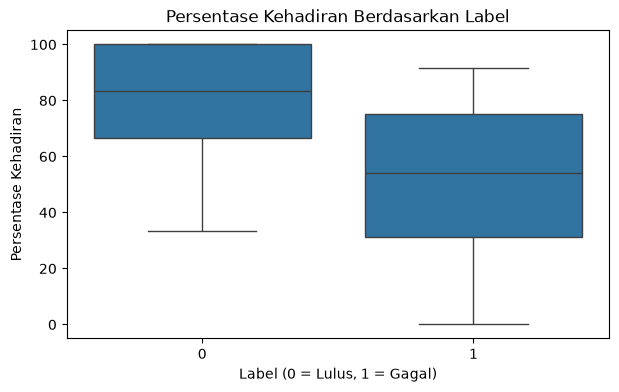

In [18]:
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df,
    x=target,
    y="Percent Attended"
)

plt.title("Persentase Kehadiran Berdasarkan Label")
plt.xlabel("Label (0 = Lulus, 1 = Gagal)")
plt.ylabel("Persentase Kehadiran")

plt.show()

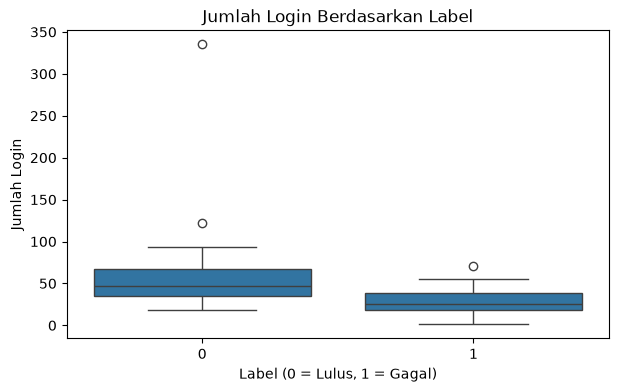

In [19]:
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df,
    x=target,
    y="Count of Module Area Logins"
)

plt.title("Jumlah Login Berdasarkan Label")
plt.xlabel("Label (0 = Lulus, 1 = Gagal)")
plt.ylabel("Jumlah Login")

plt.show()

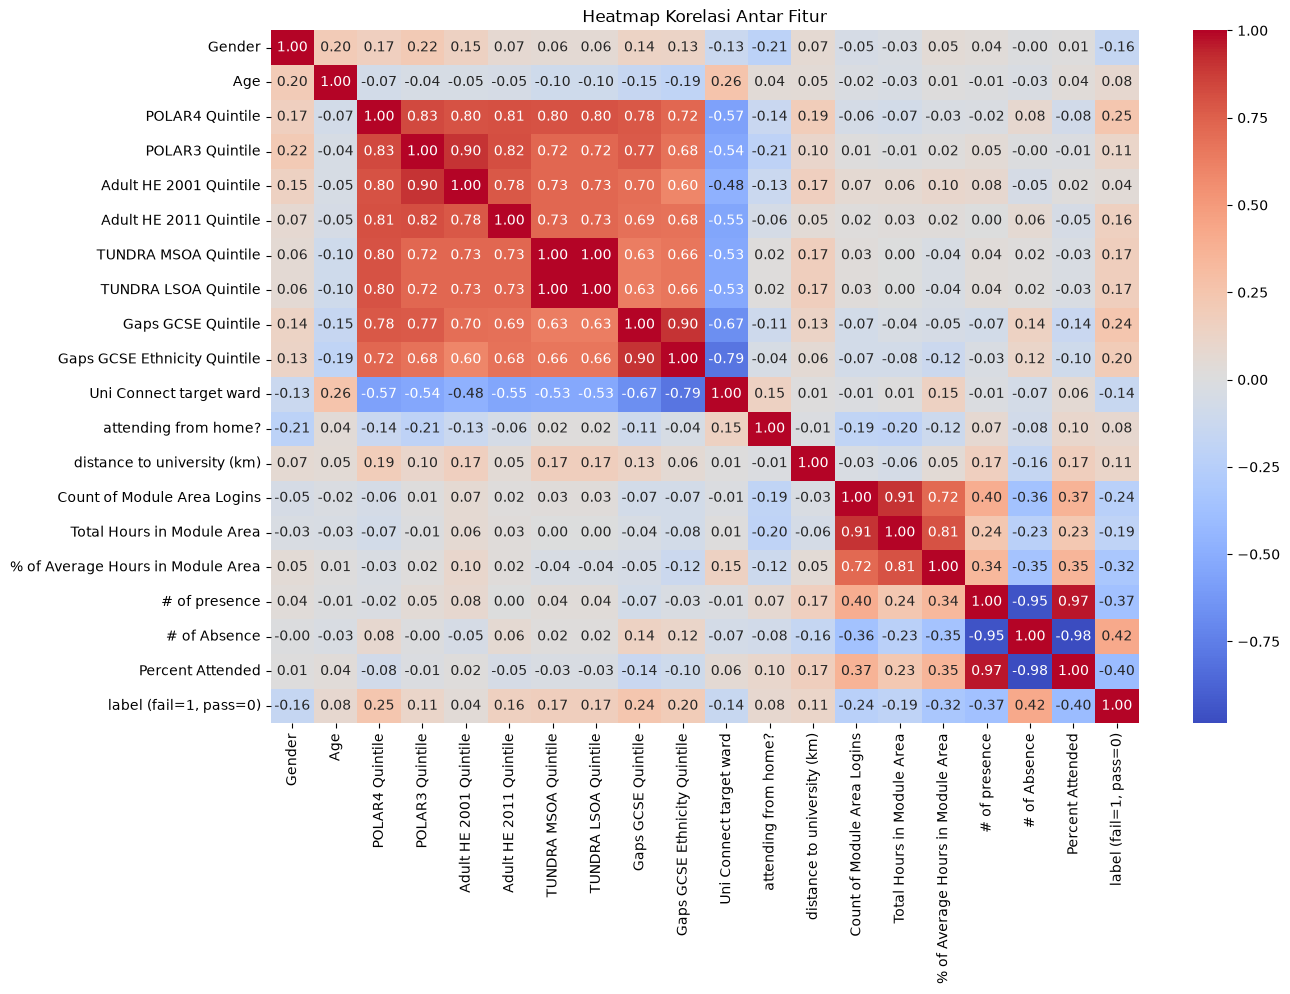

In [20]:
numerik = df.select_dtypes(include=np.number)

plt.figure(figsize=(14,9))

sns.heatmap(
    numerik.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heatmap Korelasi Antar Fitur")

plt.show()

In [21]:
numerik = df.select_dtypes(include=np.number)

for col in numerik.columns:

    if col == target:
        continue

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ]

    print(
        col,
        "Jumlah Outlier:",
        len(outlier)
    )

Gender Jumlah Outlier: 10
Age Jumlah Outlier: 6
POLAR4 Quintile Jumlah Outlier: 0
POLAR3 Quintile Jumlah Outlier: 0
Adult HE 2001 Quintile Jumlah Outlier: 0
Adult HE 2011 Quintile Jumlah Outlier: 0
TUNDRA MSOA Quintile Jumlah Outlier: 0
TUNDRA LSOA Quintile Jumlah Outlier: 0
Gaps GCSE Quintile Jumlah Outlier: 0
Gaps GCSE Ethnicity Quintile Jumlah Outlier: 8
Uni Connect target ward Jumlah Outlier: 8
attending from home? Jumlah Outlier: 0
distance to university (km) Jumlah Outlier: 7
Count of Module Area Logins Jumlah Outlier: 2
Total Hours in Module Area Jumlah Outlier: 3
% of Average Hours in Module Area Jumlah Outlier: 4
# of presence Jumlah Outlier: 2
# of Absence Jumlah Outlier: 2
Percent Attended Jumlah Outlier: 0


##Persiapan Data

In [23]:
# Menentukan kolom target
target = "label (fail=1, pass=0)"

# Menghapus fitur redundan
drop_cols = [
    "POLAR3 Quintile",
    "TUNDRA LSOA Quintile",
    "# of presence",
    "# of Absence"
]

# Memisahkan fitur dan label
X = df.drop(
    columns=[target] + drop_cols,
    errors="ignore"
)

y = df[target]

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Data:", X.shape[0])

print("\nDaftar Fitur:")
print(X.columns.tolist())

Jumlah Fitur: 15
Jumlah Data: 80

Daftar Fitur:
['Gender', 'Age', 'POLAR4 Quintile', 'Adult HE 2001 Quintile', 'Adult HE 2011 Quintile', 'TUNDRA MSOA Quintile', 'Gaps GCSE Quintile', 'Gaps GCSE Ethnicity Quintile', 'Uni Connect target ward', 'attending from home?', 'distance to university (km)', 'Count of Module Area Logins', 'Total Hours in Module Area', '% of Average Hours in Module Area', 'Percent Attended']


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", X_train.shape)
print("Jumlah Data Testing:", X_test.shape)

print("\nDistribusi Label Training:")
print(y_train.value_counts())

print("\nDistribusi Label Testing:")
print(y_test.value_counts())

Jumlah Data Training: (64, 15)
Jumlah Data Testing: (16, 15)

Distribusi Label Training:
label (fail=1, pass=0)
0    54
1    10
Name: count, dtype: int64

Distribusi Label Testing:
label (fail=1, pass=0)
0    14
1     2
Name: count, dtype: int64


In [25]:
print("Persentase Label Data Training:")
display(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nPersentase Label Data Testing:")
display(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Persentase Label Data Training:


label (fail=1, pass=0)
0    84.38
1    15.62
Name: proportion, dtype: float64


Persentase Label Data Testing:


label (fail=1, pass=0)
0    87.5
1    12.5
Name: proportion, dtype: float64

In [26]:
log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

print("Pipeline Logistic Regression berhasil dibuat")

Pipeline Logistic Regression berhasil dibuat


In [27]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

print("Pipeline Random Forest berhasil dibuat")

Pipeline Random Forest berhasil dibuat


##Modeling

In [29]:
log_model.fit(X_train, y_train)

print("Logistic Regression berhasil dilatih")

Logistic Regression berhasil dilatih


In [30]:
pred_log = log_model.predict(X_test)

print("Hasil Prediksi Logistic Regression:")
print(pred_log)

Hasil Prediksi Logistic Regression:
[1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0]


In [31]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_gagal = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

cv_log = cross_validate(
    log_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_gagal": f1_gagal
    }
)

print("Hasil Cross Validation Logistic Regression")

print(
    "Rata-rata Accuracy:",
    round(cv_log["test_accuracy"].mean(), 3)
)

print(
    "Rata-rata F1 Gagal:",
    round(cv_log["test_f1_gagal"].mean(), 3)
)

Hasil Cross Validation Logistic Regression
Rata-rata Accuracy: 0.814
Rata-rata F1 Gagal: 0.541


In [32]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 4, 8],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=cv,
    scoring=f1_gagal,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Parameter Terbaik:")
print(grid_search.best_params_)

print("\nNilai F1 Terbaik:")
print(grid_search.best_score_)

Parameter Terbaik:
{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Nilai F1 Terbaik:
0.4133333333333333


In [33]:
best_rf = grid_search.best_estimator_

print("Model Random Forest terbaik berhasil diperoleh")

Model Random Forest terbaik berhasil diperoleh


##Evaluasi Model

In [35]:
models = {
    "Logistic Regression": log_model,
    "Random Forest": best_rf
}

results = []

for name, model in models.items():

    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    precision = precision_score(
        y_test, pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_test, pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_test, pred,
        pos_label=1,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

hasil_evaluasi = pd.DataFrame(results)

display(hasil_evaluasi.round(3))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.812,0.333,0.5,0.400
1,Random Forest,0.938,1.000,0.5,0.667


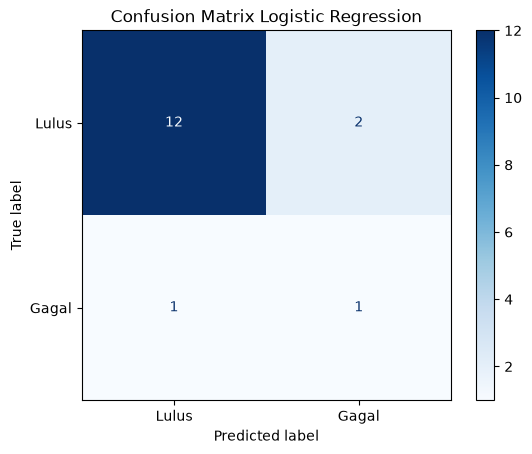

In [36]:
pred_log = log_model.predict(X_test)

cm_log = confusion_matrix(
    y_test,
    pred_log,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["Lulus", "Gagal"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix Logistic Regression")

plt.show()

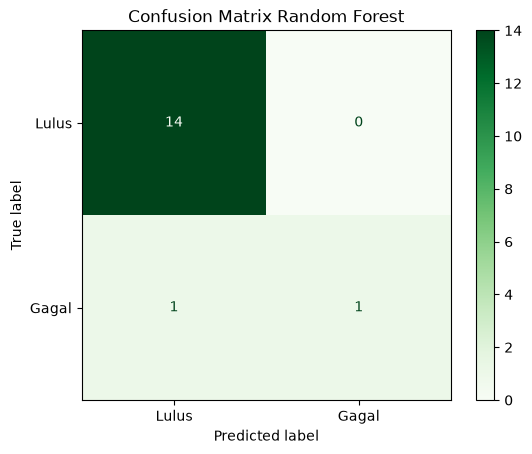

In [37]:
pred_rf = best_rf.predict(X_test)

cm_rf = confusion_matrix(
    y_test,
    pred_rf,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Lulus", "Gagal"]
)

disp.plot(cmap="Greens")

plt.title("Confusion Matrix Random Forest")

plt.show()

In [38]:
print("Classification Report Logistic Regression")

print(
    classification_report(
        y_test,
        pred_log,
        target_names=["Lulus", "Gagal"],
        zero_division=0
    )
)

print("\nClassification Report Random Forest")

print(
    classification_report(
        y_test,
        pred_rf,
        target_names=["Lulus", "Gagal"],
        zero_division=0
    )
)

Classification Report Logistic Regression
              precision    recall  f1-score   support

       Lulus       0.92      0.86      0.89        14
       Gagal       0.33      0.50      0.40         2

    accuracy                           0.81        16
   macro avg       0.63      0.68      0.64        16
weighted avg       0.85      0.81      0.83        16


Classification Report Random Forest
              precision    recall  f1-score   support

       Lulus       0.93      1.00      0.97        14
       Gagal       1.00      0.50      0.67         2

    accuracy                           0.94        16
   macro avg       0.97      0.75      0.82        16
weighted avg       0.94      0.94      0.93        16



In [39]:
best_index = hasil_evaluasi["F1-Score"].idxmax()

best_name = hasil_evaluasi.loc[
    best_index, "Model"
]

if best_name == "Logistic Regression":
    best_model = log_model
else:
    best_model = best_rf

print("Model Terbaik:", best_name)

print(
    "Nilai F1-Score:",
    round(
        hasil_evaluasi.loc[best_index, "F1-Score"],
        3
    )
)

Model Terbaik: Random Forest
Nilai F1-Score: 0.667


In [40]:
if best_name == "Random Forest":

    importance = best_model.named_steps[
        "model"
    ].feature_importances_

else:

    importance = np.abs(
        best_model.named_steps[
            "model"
        ].coef_[0]
    )

fitur_penting = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": importance
})

fitur_penting = fitur_penting.sort_values(
    by="Importance",
    ascending=False
)

display(fitur_penting.head(10))

,Fitur,Importance
13,% of Average Hours in Module Area,0.240311
12,Total Hours in Module Area,0.161792
11,Count of Module Area Logins,0.148334
14,Percent Attended,0.101143
10,distance to university (km),0.068775
2,POLAR4 Quintile,0.058099
1,Age,0.046602
3,Adult HE 2001 Quintile,0.039023
4,Adult HE 2011 Quintile,0.034734
6,Gaps GCSE Quintile,0.034229


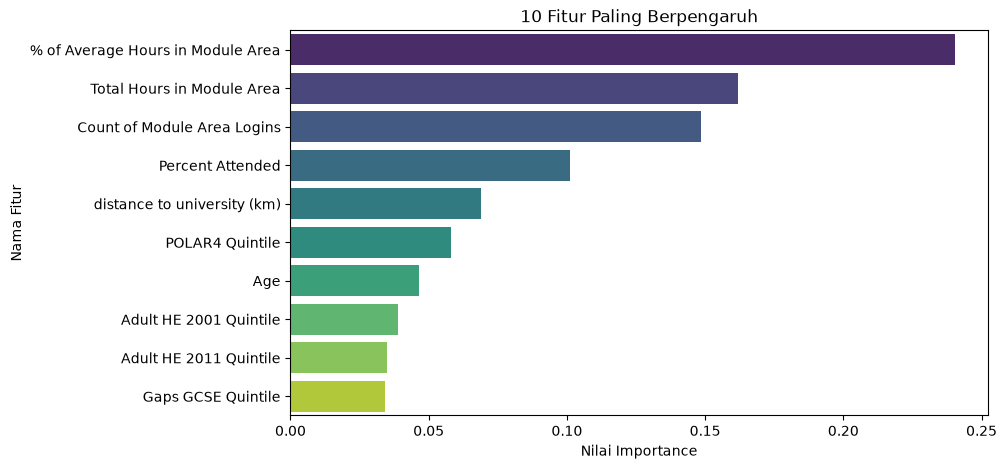

In [41]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=fitur_penting.head(10),
    x="Importance",
    y="Fitur",
    hue="Fitur",
    palette="viridis",
    legend=False
)

plt.title("10 Fitur Paling Berpengaruh")
plt.xlabel("Nilai Importance")
plt.ylabel("Nama Fitur")

plt.show()

##Tes Prediksi dengan Data Random

In [43]:
np.random.seed(42)

data_baru = pd.DataFrame()

for col in X.columns:

    nilai = X[col].dropna()

    if "Quintile" in col:

        data_baru[col] = np.random.randint(
            1, 6, size=5
        )

    elif set(nilai.unique()).issubset({0, 1}):

        data_baru[col] = np.random.randint(
            0, 2, size=5
        )

    elif pd.api.types.is_integer_dtype(X[col]):

        minimum = int(nilai.min())
        maksimum = int(nilai.max())

        data_baru[col] = np.random.randint(
            minimum,
            maksimum + 1,
            size=5
        )

    else:

        minimum = nilai.min()
        maksimum = nilai.max()

        data_baru[col] = np.random.uniform(
            minimum,
            maksimum,
            size=5
        )

print("Lima Data Mahasiswa Baru:")

display(data_baru)

Lima Data Mahasiswa Baru:


,Gender,Age,POLAR4 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,Percent Attended
0,0,26,3,5,5,4,2,4,0,1,122.303202,264,116.243034,5.336311,92.187424
1,1,39,3,2,1,1,4,1,0,0,5.066529,35,54.707240,4.266609,8.849250
2,0,25,5,4,4,1,4,3,0,1,73.268929,206,91.255132,5.170807,19.598286
3,0,44,4,2,2,3,3,5,0,1,76.483976,81,95.928450,4.925063,4.522729
4,0,37,3,4,5,3,4,3,1,1,216.818211,50,32.455320,3.291631,32.533033


In [44]:
prediksi = best_model.predict(data_baru)

probabilitas = best_model.predict_proba(data_baru)

print("Hasil Prediksi Mahasiswa:")
print(prediksi)

Hasil Prediksi Mahasiswa:
[0 0 0 0 0]


In [45]:
hasil_prediksi = data_baru.copy()

hasil_prediksi["Prediksi Label"] = prediksi

hasil_prediksi["Status"] = np.where(
    prediksi == 1,
    "Gagal",
    "Lulus"
)

hasil_prediksi["Probabilitas Gagal"] = probabilitas[:, 1]

hasil_prediksi["Probabilitas Lulus"] = probabilitas[:, 0]

display(hasil_prediksi.round(3))

,Gender,Age,POLAR4 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,Percent Attended,Prediksi Label,Status,Probabilitas Gagal,Probabilitas Lulus
0,0,26,3,5,5,4,2,4,0,1,122.303,264,116.243,5.336,92.187,0,Lulus,0.14,0.86
1,1,39,3,2,1,1,4,1,0,0,5.067,35,54.707,4.267,8.849,0,Lulus,0.12,0.88
2,0,25,5,4,4,1,4,3,0,1,73.269,206,91.255,5.171,19.598,0,Lulus,0.11,0.89
3,0,44,4,2,2,3,3,5,0,1,76.484,81,95.928,4.925,4.523,0,Lulus,0.16,0.84
4,0,37,3,4,5,3,4,3,1,1,216.818,50,32.455,3.292,32.533,0,Lulus,0.17,0.83


In [46]:
for i in range(len(hasil_prediksi)):

    print("Mahasiswa", i + 1)

    print(
        "Status:",
        hasil_prediksi.iloc[i]["Status"]
    )

    print(
        "Probabilitas Gagal:",
        round(
            hasil_prediksi.iloc[i]["Probabilitas Gagal"] * 100,
            2
        ), "%"
    )

    print(
        "Probabilitas Lulus:",
        round(
            hasil_prediksi.iloc[i]["Probabilitas Lulus"] * 100,
            2
        ), "%"
    )

    print("-" * 40)

Mahasiswa 1
Status: Lulus
Probabilitas Gagal: 14.0 %
Probabilitas Lulus: 86.0 %
----------------------------------------
Mahasiswa 2
Status: Lulus
Probabilitas Gagal: 12.0 %
Probabilitas Lulus: 88.0 %
----------------------------------------
Mahasiswa 3
Status: Lulus
Probabilitas Gagal: 11.0 %
Probabilitas Lulus: 89.0 %
----------------------------------------
Mahasiswa 4
Status: Lulus
Probabilitas Gagal: 16.0 %
Probabilitas Lulus: 84.0 %
----------------------------------------
Mahasiswa 5
Status: Lulus
Probabilitas Gagal: 17.0 %
Probabilitas Lulus: 83.0 %
----------------------------------------
